In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/3")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "3":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 3.4 ブートローダからピクセルを描く (`Drawing Pixels from Bootloader`)
## — UEFI GOP (Graphics Output Protocol) の探査・VRAM メモリマッピング・走査線ストライドの数理と全画面描画

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.4_Drawing_Pixels_from_Bootloader.ipynb)

---

### 🎯 本節の学習目標と到達点
前節（3.3節）において、私たちはブートローダ（`MikanLoaderPkg`）からカーネル ELF ファイル（`kernel.elf`）をメモリ上の `0x100000`（1MiB境界）へロードし、`ExitBootServices` によって UEFI ファームウェアから OS への主権移譲を完了しました。しかし、前節までの画面出力は、UEFI が提供するレガシーな文字表示プロトコル（`ConOut->OutputString`）による白黒テキストのみに限定されていました。

MikanOS は**マウス操作が可能なグラフィカルなマルチウィンドウ OS** を目指します。グラフィカルな画面を構築するためには、文字コードを渡すだけのインターフェースから脱却し、**ディスプレイの1ピクセル（画素）単位の色を直接制御するハードウェア機構** を掌握しなければなりません。

本節では、UEFI 仕様における標準グラフィックスインターフェースである **GOP (*Graphics Output Protocol*)** を探査・獲得し、ビデオメモリ（**VRAM / MMIO: *Memory-Mapped I/O***）の物理アドレスを特定して、画面全体を白色に塗りつぶす（`frame_buffer[i] = 255`）低レイヤグラフィックスプログラミングの第一歩を完全に解明します。

| 概念・技術用語 | 英語表記 / 略称 | 本節における役割と重要性 |
|---|---|---|
| **グラフィックス出力プロトコル** | **GOP** (*Graphics Output Protocol*) | UEFI ファームウェアが提供するハードウェア非依存の 2D グラフィックス制御プロトコル |
| **ビデオメモリ / フレームバッファ** | **VRAM** / **FrameBuffer** | ディスプレイに表示される全画素の色データを保持する連続したメモリ領域（PCI MMIO） |
| **メモリマップドI/O** | **MMIO** (*Memory-Mapped I/O*) | グラフィックスカード等の周辺機器レジスタや VRAM をメインメモリ空間にマッピングする方式 |
| **走査線ストライド** | **Stride** / `PixelsPerScanLine` | 1走査線（1行）を構成する全ピクセル数（ハードウェアアライメントによるパディング領域を含む） |
| **ピクセルフォーマット** | **PixelFormat** | 1ピクセルを構成するバイト順序（RGBR, BGRR, BitMask 等の色の並び順） |
| **プロトコル GUID** | `gEfiGraphicsOutputProtocolGuid` | UEFI 内で GOP インターフェースを一意に識別するための 128 ビット識別子 |
| **ハンドルバッファ探索** | `LocateHandleBuffer` | 特定の GUID を実装したデバイスハンドル群を動的に探索・列挙するブートサービス API |

## 1. なぜブートローダからピクセルを描くのか？（テキスト表示の限界と GOP）

### 1.1 レガシー BIOS 時代のグラフィックス初期化の悲劇
1980年代〜2000年代初頭の PC/AT 互換機（レガシー BIOS 環境）において、画面にグラフィックスを表示することは極めて困難な儀式でした：
1. **16ビットリアルモードの制約**: BIOS 割り込み `INT 10h, AH=00h` を発行して **VGA Mode 13h**（解像度 320×200、256色パレットカラー、VRAM アドレス `0xA0000`）へ切り替える必要がありました。
2. **保護モード・ロングモードでの BIOS 呼び出し不能**: CPU を 32ビット保護モードや 64ビットロングモードへ移行させた後では、16ビットリアルモード前提の BIOS 割り込みを直接呼ぶことができません。高解像度（VESA VBE: 1024×768 等）を設定するためには、CPU を一時的にリアルモードへ戻す（または仮想86モードを使う）か、極めて難解なグラフィックスチップセット専用ドライバを OS 自前で書く必要がありました。

### 1.2 UEFI GOP (Graphics Output Protocol) による革命
UEFI はこのレガシーな問題を完全に解決しました。UEFI 仕様では、プラットフォーム初期化フェーズでファームウェア自身がビデオカード（Intel HD Graphics, AMD Radeon, NVIDIA, または QEMU の Bochs/Cirrus/virtio-gpu）の初期化を済ませており、**OS がブートする時点で既に 64ビットネイティブの高解像度リニアフレームバッファ（Linear Framebuffer）が利用可能な状態** に整備されています。

ブートローダがやるべきことは、UEFI ブートサービスを通じて **GOP (*Graphics Output Protocol*)** を問い合わせ、**「フレームバッファの先頭物理アドレス（`FrameBufferBase`）」** と **「画面の解像度（幅・高さ・ストライド）」** を受け取るだけです。このアドレスさえ分かれば、CPU は通常のメモリポインタ操作（`*ptr = color`）を行うだけで、ディスプレイの任意のピクセルを自在に書き換えることができます。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:12382: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


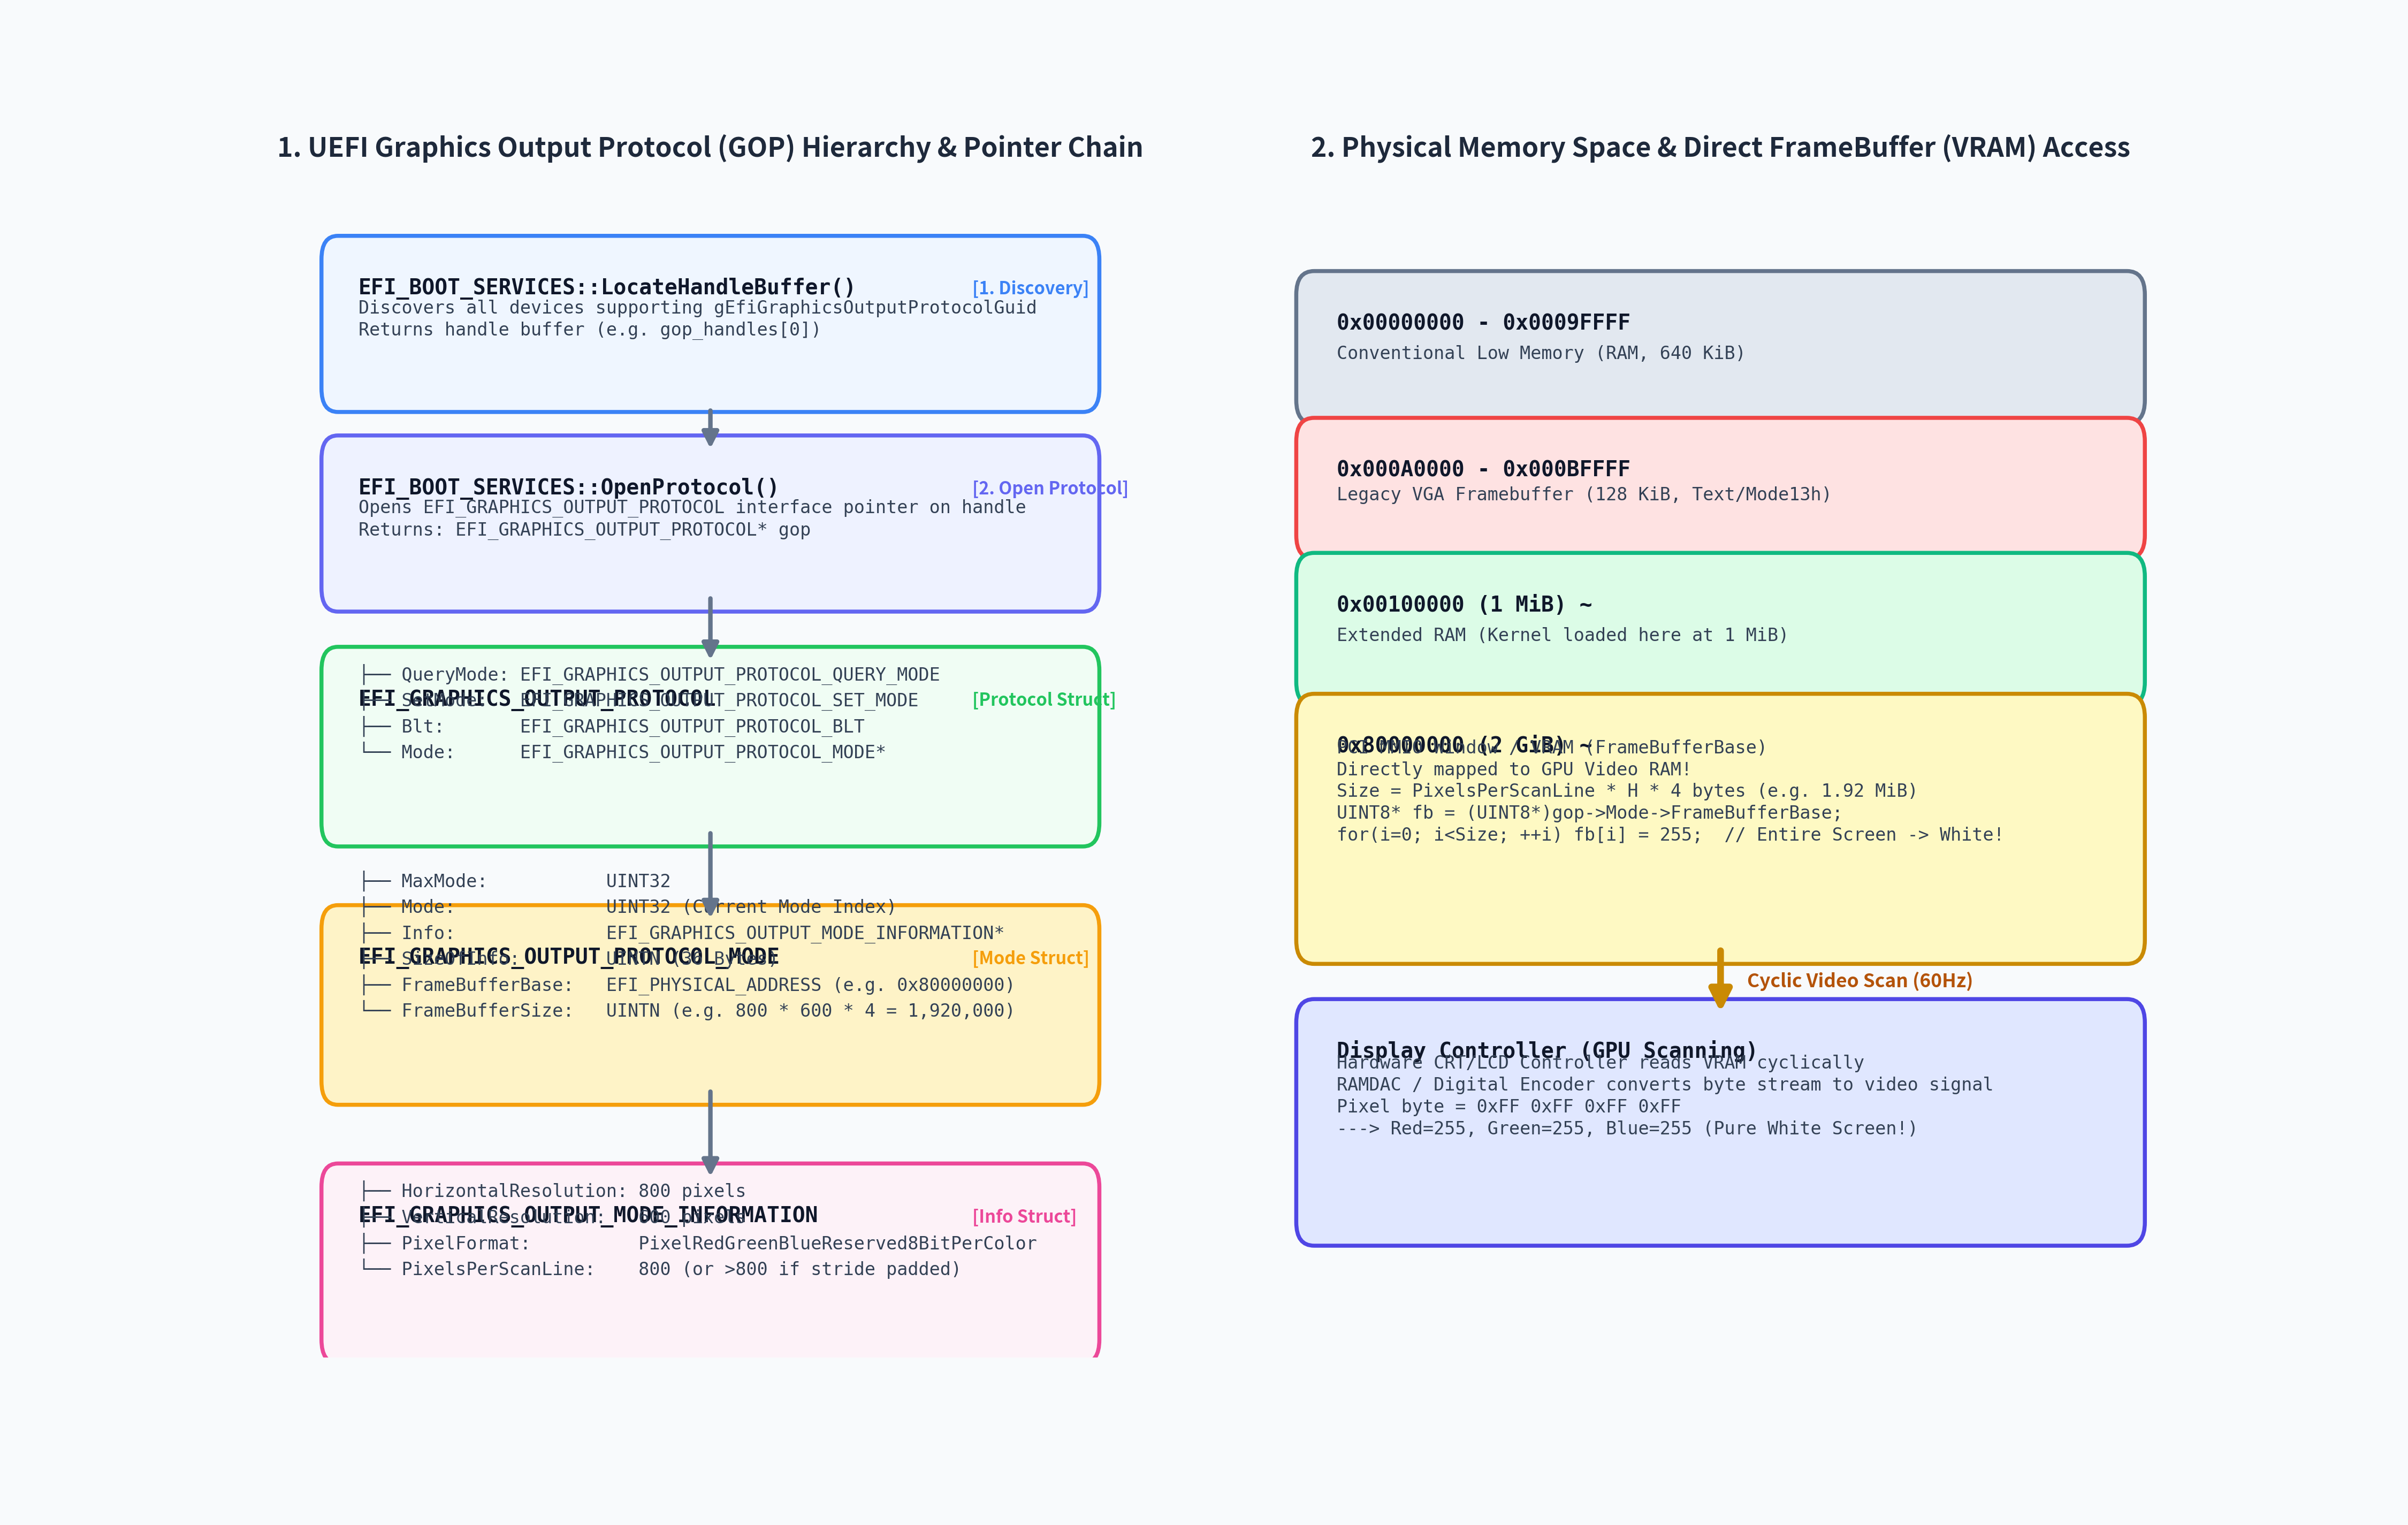

In [2]:
# === GOP アーキテクチャ図版 (fig3_07) の生成・表示 ===
from pathlib import Path
from IPython.display import Image, display
import common

fig7_path = Path("result/fig3_07_uefi_gop_framebuffer_architecture.png")
common.plot_uefi_gop_framebuffer_architecture(fig7_path)
display(Image(filename=str(fig7_path), width=900))


## 2. UEFI GOP (Graphics Output Protocol) の全容と GUID 解決

### 2.1 GUID と LocateHandleBuffer による GOP 探索フロー
UEFI の世界では、ハードウェアや機能の抽象化インターフェースを **「プロトコル (Protocol)」** と呼びます。各プロトコルは 128 ビットの **GUID (*Globally Unique Identifier*)** によって世界中で一意に識別されます。

GOP の GUID は EDK II のヘッダ（`<Protocol/GraphicsOutput.h>`）において以下のように定義されています：
```c
// gEfiGraphicsOutputProtocolGuid (9042A9DE-23DC-4A38-96FB-7ADED080516A)
EFI_GUID gEfiGraphicsOutputProtocolGuid = {
    0x9042a9de, 0x23dc, 0x4a38,
    { 0x96, 0xfb, 0x7a, 0xde, 0xd0, 0x80, 0x51, 0x6a }
};
```

ブートローダ（`Main.c`）は、UEFI ブートサービステーブル（`gBS`）の `LocateHandleBuffer` API を呼び出すことで、この GUID をサポートするすべてのデバイスハンドルを配列として取得します：

```mermaid
sequenceDiagram
    autonumber
    participant App as MikanLoader (UefiMain)
    participant BS as gBS (BootServices)
    participant GPU as GOP Device Handle

    App->>BS: LocateHandleBuffer(ByProtocol, &gEfiGraphicsOutputProtocolGuid, ...)
    BS-->>App: num_gop_handles = 1, gop_handles = [0x7E3F...]
    App->>BS: OpenProtocol(gop_handles[0], &gEfiGraphicsOutputProtocolGuid, (VOID**)&gop, ...)
    BS-->>App: gop (EFI_GRAPHICS_OUTPUT_PROTOCOL*)
    App->>BS: FreePool(gop_handles)
    Note over App: gop->Mode->FrameBufferBase を取得しピクセル描画可能に！
```

### 2.2 MikanOS における OpenGOP 実装の徹底解説
MikanOS 公式リポジトリの `day03b` における `OpenGOP` 関数の実装は以下の通りです：

```c
EFI_STATUS OpenGOP(EFI_HANDLE image_handle,
                   EFI_GRAPHICS_OUTPUT_PROTOCOL** gop) {
  UINTN num_gop_handles = 0;
  EFI_HANDLE* gop_handles = NULL;
  gBS->LocateHandleBuffer(
      ByProtocol,
      &gEfiGraphicsOutputProtocolGuid,
      NULL,
      &num_gop_handles,
      &gop_handles);

  gBS->OpenProtocol(
      gop_handles[0],
      &gEfiGraphicsOutputProtocolGuid,
      (VOID**)gop,
      image_handle,
      NULL,
      EFI_OPEN_PROTOCOL_BY_HANDLE_PROTOCOL);

  FreePool(gop_handles);

  return EFI_SUCCESS;
}
```

> [!IMPORTANT]
> **二重ポインタと FreePool の必然性**:
> 1. `EFI_GRAPHICS_OUTPUT_PROTOCOL** gop`: 呼び出し元のポインタ変数自身を書き換えるため、第2章で学んだ **二重ポインタ（`void**`）** を使用しています。
> 2. `FreePool(gop_handles)`: `LocateHandleBuffer` はハンドルを格納するためのメモリバッファを内部で動的に確保（`AllocatePool`）して返します。取得完了後に `FreePool` で解放しないとメモリリークになります。

In [3]:
# === Python による UEFI GOP プロトコル探索とハンドルオープンシミュレーション ===
from common import UefiGopSimulator, UefiGraphicsPixelFormat, EFI_GRAPHICS_OUTPUT_PROTOCOL_GUID

# 800x600 解像度、RGB 予約 8bit フォーマットの仮想 GOP デバイスを初期化
sim = UefiGopSimulator(
    horizontal_resolution=800,
    vertical_resolution=600,
    pixels_per_scan_line=800,
    pixel_format=UefiGraphicsPixelFormat.PixelRedGreenBlueReserved8BitPerColor,
    frame_buffer_base=0x80000000,
)

print("=== UEFI GOP Protocol Discovery Simulation ===")
print(f"Target Protocol GUID  : {EFI_GRAPHICS_OUTPUT_PROTOCOL_GUID}")
print(f"Discovered Handles    : {sim.handles}")

# OpenProtocol を実行
success = sim.open_gop("GopHandle0")
print(f"OpenProtocol Status   : {'EFI_SUCCESS' if success else 'EFI_NOT_FOUND'}")
print(f"Pixel Format String   : {sim.get_pixel_format_unicode()}")
print(f"Resolution            : {sim.info.horizontal_resolution} x {sim.info.vertical_resolution}")
print(f"PixelsPerScanLine     : {sim.info.pixels_per_scan_line} pixels/line")
print(f"FrameBuffer Base Addr : 0x{sim.mode.frame_buffer_base:08X}")
print(f"FrameBuffer Total Size: {sim.mode.frame_buffer_size:,} bytes ({sim.mode.frame_buffer_size / (1024*1024):.2f} MiB)")


=== UEFI GOP Protocol Discovery Simulation ===
Target Protocol GUID  : 9042a9de-23dc-4a38-96fb-7aded080516a
Discovered Handles    : ['GopHandle0']
OpenProtocol Status   : EFI_SUCCESS
Pixel Format String   : PixelRedGreenBlueReserved8BitPerColor
Resolution            : 800 x 600
PixelsPerScanLine     : 800 pixels/line
FrameBuffer Base Addr : 0x80000000
FrameBuffer Total Size: 1,920,000 bytes (1.83 MiB)


## 3. GOP モード構造体ポインタチェーンと階層データ構造

### 3.1 3段階のポインタチェーン構造
`OpenGOP` で取得した `gop` 変数から解像度や VRAM アドレスを取得するには、以下の **3段階の階層構造体ポインタチェーン** を辿ります：

$$\text{gop} \longrightarrow \text{Mode} \longrightarrow \text{Info}$$

```text
+-----------------------------------------+
| EFI_GRAPHICS_OUTPUT_PROTOCOL            |
|   ├── QueryMode (Function Pointer)      |
|   ├── SetMode   (Function Pointer)      |
|   ├── Blt       (Function Pointer)      |
|   └── Mode* ------------------------------------------------+
+-----------------------------------------+                 |
                                                            v
+-------------------------------------------------------------+
| EFI_GRAPHICS_OUTPUT_PROTOCOL_MODE                           |
|   ├── MaxMode           : UINT32                            |
|   ├── Mode              : UINT32 (Current Mode Index)       |
|   ├── Info* ----------------------------------------------------+
|   ├── SizeOfInfo        : UINTN (36 Bytes)                  |   |
|   ├── FrameBufferBase   : EFI_PHYSICAL_ADDRESS (64-bit VRAM)|   |
|   └── FrameBufferSize   : UINTN (Total VRAM bytes)          |   |
+-------------------------------------------------------------+   |
                                                                  v
+-------------------------------------------------------------------+
| EFI_GRAPHICS_OUTPUT_MODE_INFORMATION                              |
|   ├── Version              : UINT32                               |
|   ├── HorizontalResolution : UINT32 (e.g. 800)                    |
|   ├── VerticalResolution   : UINT32 (e.g. 600)                    |
|   ├── PixelFormat          : EFI_GRAPHICS_PIXEL_FORMAT            |
|   ├── PixelInformation     : EFI_PIXEL_BITMASK (Red, Green, Blue) |
|   └── PixelsPerScanLine    : UINT32 (e.g. 800 or 832)             |
+-------------------------------------------------------------------+
```

### 3.2 ピクセルフォーマット（PixelFormat）の列挙とバイトオーダー
UEFI 仕様書で定められた `EFI_GRAPHICS_PIXEL_FORMAT` は以下の 5 つの値をとります：

| 列挙値 | 整数値 | メモリバイト配置 (低位アドレス $\to$ 高位アドレス) | リトルエンディアン 32bit int |
|---|:---:|---|:---:|
| `PixelRedGreenBlueReserved8BitPerColor` | 0 | `[Byte 0: R]` `[Byte 1: G]` `[Byte 2: B]` `[Byte 3: 予約]` | `0xXXBBGGRR` |
| `PixelBlueGreenRedReserved8BitPerColor` | 1 | `[Byte 0: B]` `[Byte 1: G]` `[Byte 2: R]` `[Byte 3: 予約]` | `0xXXRRGGBB` |
| `PixelBitMask` | 2 | `PixelInformation` のビットマスクに従う任意形式 | カスタム |
| `PixelBltOnly` | 3 | リニアフレームバッファ直接アクセス不可（`Blt` API のみ使用可能） | 非対応 |
| `PixelFormatMax` | 4 | 列挙型の最大値（番兵） | - |

> [!NOTE]
> 現代の x86-64 PC や QEMU では、ほとんどの場合 `PixelRedGreenBlueReserved8BitPerColor`（RGBA順）または `PixelBlueGreenRedReserved8BitPerColor`（BGRA順）のいずれかが選択されます。各色成分は 8 ビット（0〜255）で表現され、1画素あたり合計 4 バイト（32 ビット）を消費します。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:12635: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


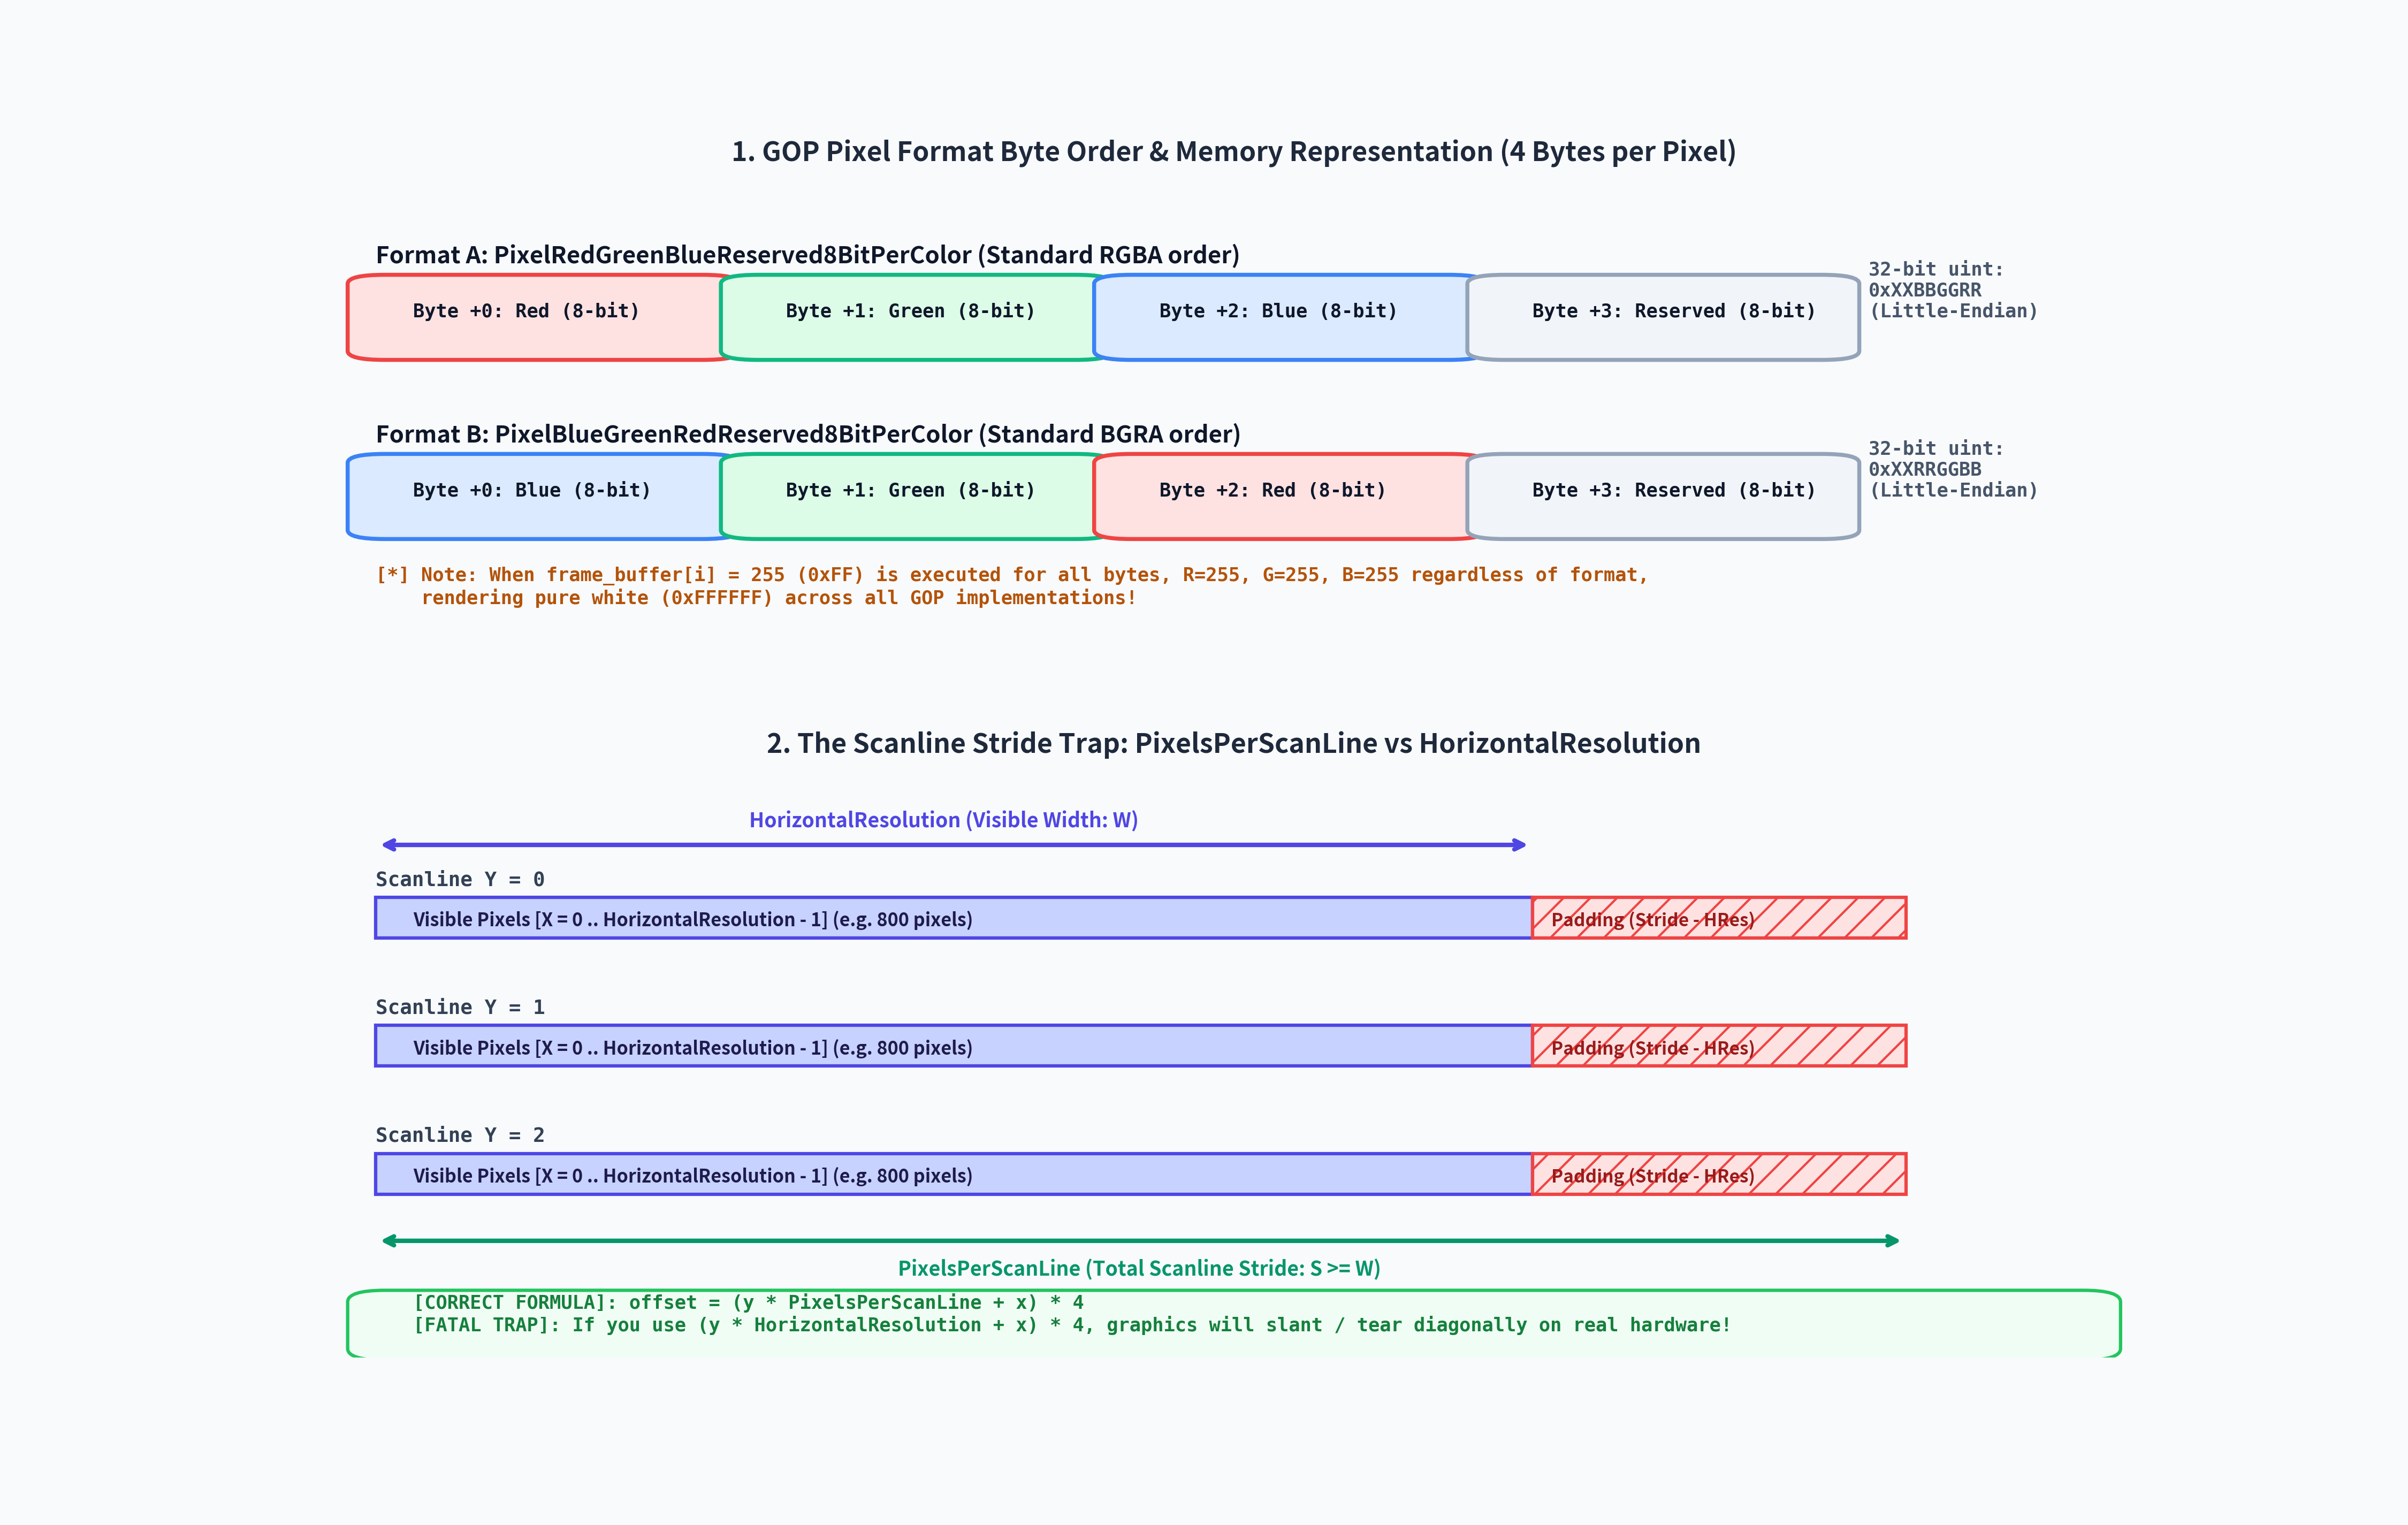

In [4]:
# === ピクセルフォーマット & 走査線ストライド図版 (fig3_08) の生成・表示 ===
fig8_path = Path("result/fig3_08_pixel_format_and_scanline_stride.png")
common.plot_pixel_format_and_scanline_stride(fig8_path)
display(Image(filename=str(fig8_path), width=900))


## 4. 走査線ストライド (PixelsPerScanLine) の数理と致命的な落とし穴

### 4.1 なぜ HorizontalResolution ＝ PixelsPerScanLine ではないのか？
多くのプログラミング初学者が OS 自作で最初に直面する最も恐ろしいバグが **「走査線ストライドの罠」** です。

一見すると、画面の幅が 800 ピクセルであれば、1行あたりのピクセル数も 800 であるかのように思えます。しかし、現代の GPU ハードウェアやメモリアーキテクチャには以下の物理的制約があります：
- **メモリアクセスのアライメント制約**: GPU やメモリコントローラは、64バイト（キャッシュライン）や 128バイト、256バイトの境界でメモリアクセスを行う際に最も高いバススループットを発揮します。
- もし画面解像度が 1366×768 のような中途半端な幅である場合、$1366 \times 4 = 5464$ バイトとなり、256 の倍数（アライメント境界）に揃いません。
- そこで GPU は、1行の末尾に**画面には表示されない不可視パディングピクセル（余白領域）** を追加し、全体のストライドを 1376 や 1408 などキリの良い数値に切り上げます。

この「パディングを含めた 1 行あたりの全ピクセル数」こそが **`PixelsPerScanLine`（走査線ストライド $S$）** です。

### 4.2 物理アドレス計算式の完全導出
2次元座標 $(x, y)$ のピクセルが VRAM 先頭（`FrameBufferBase`）から何バイト目にあるかを求める数式は以下の通りです：

$$\text{ByteOffset}(x, y) = (y \times \text{PixelsPerScanLine} + x) \times 4$$

物理アドレスとしては次のようになります：
$$\text{PhysicalAddress}(x, y) = \text{FrameBufferBase} + \left(y \times \text{PixelsPerScanLine} + x\right) \times 4$$

> [!CAUTION]
> **【致命的バグ】もし `HorizontalResolution`（幅 $W$）を使って計算したらどうなるか？**
> 誤った式: $\text{Offset}_{bug}(x, y) = (y \times \text{HorizontalResolution} + x) \times 4$
> この場合、行 $y$ が 1 進むごとに $(S - W) \times 4$ バイトのズレ（誤差）が蓄積します。
> その結果、**垂直に引いたはずの直線が斜めに歪み、画面全体の画像が激しく引き裂かれたように崩壊（Skewing / Slanting）** します！

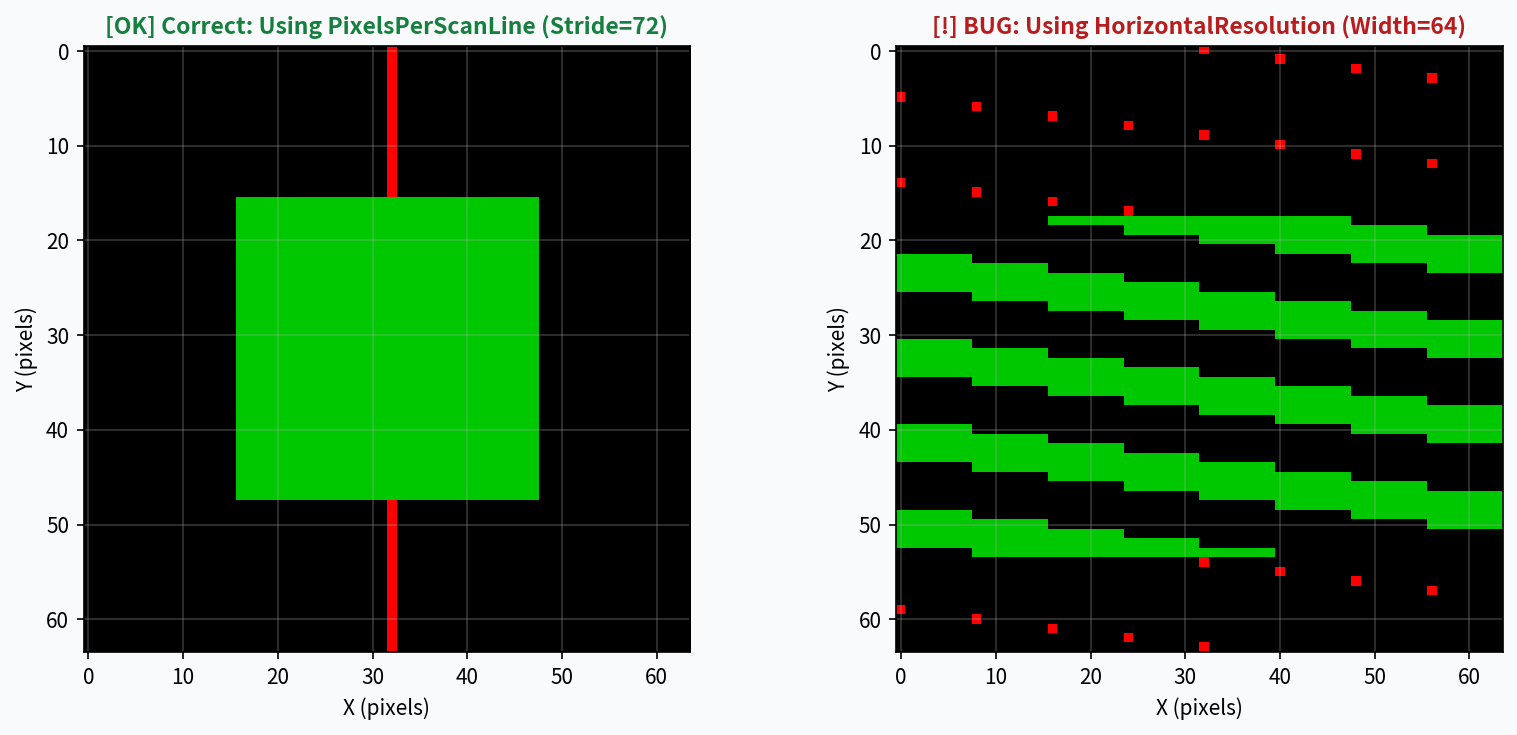

観察: バグ画像では走査線ごとに (72 - 64) * 4 = 32バイトずつ左にズレていき、正方形と直線が斜めに激しく崩壊していることが確認できます！


In [5]:
# === Python による「正しいストライド計算」vs「ストライド無視のバグ計算」の視覚的比較 ===
import numpy as np
import matplotlib.pyplot as plt

# 解像度 64x64、GPU ストライドが 72（余白 8 ピクセル = 32 バイトパディング）の環境を模倣
W, H, Stride = 64, 64, 72
vram_sim = bytearray(Stride * H * 4)

# VRAM に中央の赤い垂直線 (X = 32) と、青い正方形を描画する（正しいストライド計算を使用）
for y in range(H):
    # 垂直線 X = 32
    off = (y * Stride + 32) * 4
    vram_sim[off + 0] = 255  # R
    vram_sim[off + 1] = 0    # G
    vram_sim[off + 2] = 0    # B

# 正方形 (X: 16..48, Y: 16..48) を緑色で塗りつぶし
for y in range(16, 48):
    for x in range(16, 48):
        off = (y * Stride + x) * 4
        vram_sim[off + 0] = 0
        vram_sim[off + 1] = 200
        vram_sim[off + 2] = 0

# 1. 正しいストライド (Stride=72) で読み出した画像
img_correct = np.zeros((H, W, 3), dtype=np.uint8)
for y in range(H):
    for x in range(W):
        off = (y * Stride + x) * 4
        img_correct[y, x] = [vram_sim[off], vram_sim[off+1], vram_sim[off+2]]

# 2. 誤って HorizontalResolution (W=64) でオフセット計算した画像（バグ再現）
img_buggy = np.zeros((H, W, 3), dtype=np.uint8)
for y in range(H):
    for x in range(W):
        off_bug = (y * W + x) * 4  # <!=== FATAL BUG: W instead of Stride!
        if off_bug + 3 < len(vram_sim):
            img_buggy[y, x] = [vram_sim[off_bug], vram_sim[off_bug+1], vram_sim[off_bug+2]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), facecolor="#F8FAFC")
ax1.imshow(img_correct)
ax1.set_title("[OK] Correct: Using PixelsPerScanLine (Stride=72)", fontsize=11, fontweight="bold", color="#15803D")
ax1.set_xlabel("X (pixels)"); ax1.set_ylabel("Y (pixels)")

ax2.imshow(img_buggy)
ax2.set_title("[!] BUG: Using HorizontalResolution (Width=64)", fontsize=11, fontweight="bold", color="#B91C1C")
ax2.set_xlabel("X (pixels)"); ax2.set_ylabel("Y (pixels)")

plt.tight_layout()
plt.show()
print("観察: バグ画像では走査線ごとに (72 - 64) * 4 = 32バイトずつ左にズレていき、正方形と直線が斜めに激しく崩壊していることが確認できます！")


## 5. フレームバッファへの直接書き込みと全画面白色クリア

### 5.1 MikanOS Day03b の実装コード
MikanOS の `UefiMain`（`Main.c`）に追加された描画処理は、拍子抜けするほどシンプルかつ美しいコードです：

```c
// #@@range_begin(gop)
EFI_GRAPHICS_OUTPUT_PROTOCOL* gop;
OpenGOP(image_handle, &gop);
Print(L"Resolution: %ux%u, Pixel Format: %s, %u pixels/line\n",
    gop->Mode->Info->HorizontalResolution,
    gop->Mode->Info->VerticalResolution,
    GetPixelFormatUnicode(gop->Mode->Info->PixelFormat),
    gop->Mode->Info->PixelsPerScanLine);
Print(L"Frame Buffer: 0x%0lx - 0x%0lx, Size: %lu bytes\n",
    gop->Mode->FrameBufferBase,
    gop->Mode->FrameBufferBase + gop->Mode->FrameBufferSize,
    gop->Mode->FrameBufferSize);

UINT8* frame_buffer = (UINT8*)gop->Mode->FrameBufferBase;
for (UINTN i = 0; i < gop->Mode->FrameBufferSize; ++i) {
  frame_buffer[i] = 255;
}
// #@@range_end(gop)
```

### 5.2 なぜ `frame_buffer[i] = 255` で画面が真っ白になるのか？
このコードの最も興味深い点は、**ピクセルフォーマット（RGBR か BGRR か）を一切条件分岐していない** 点です。

1. `FrameBufferSize` は VRAM 全体のバイト数です（例えば 800×600×4 = 1,920,000 バイト）。
2. ループによって、VRAM 内のすべてのバイトに `255`（16進数で `0xFF`）が書き込まれます。
3. ピクセルの 4 バイト（Byte0, Byte1, Byte2, Byte3）すべてが `0xFF` になります。
   - フォーマットが `PixelRedGreenBlueReserved8BitPerColor` の場合：
     $$\text{Red} = 255, \quad \text{Green} = 255, \quad \text{Blue} = 255$$
   - フォーマットが `PixelBlueGreenRedReserved8BitPerColor` の場合：
     $$\text{Blue} = 255, \quad \text{Green} = 255, \quad \text{Red} = 255$$
4. 光の三原色（赤・緑・青）がすべて最大輝度（255）で発光するため、フォーマットが RGBR であろうと BGRR であろうと、**完全に均一な純白色（#FFFFFF）** が画面いっぱいに描画されます！

これは、フォーマット判定ロジックを実装する前の最小ステップとして、極めて洗練された教育的設計です。

In [6]:
# === ホスト側 C++20 スタンドアロン検証コードのコンパイルとテスト実行 ===
import subprocess

# CMake ビルドディレクトリでターゲットをビルド
cmd_build = ["cmake", "--build", "../build", "--target", "ch03_gop_sim"]
res_build = subprocess.run(cmd_build, capture_output=True, text=True)
print("CMake Build Output:")
print(res_build.stdout.strip() if res_build.stdout else "Target up to date.")

# テストスイートの実行
cmd_run = ["../build/bin/ch03_gop_sim", "--test"]
res_run = subprocess.run(cmd_run, capture_output=True, text=True)
print("\nC++20 Execution Result:")
print(res_run.stdout)
assert res_run.returncode == 0, f"C++20 test failed with code {res_run.returncode}"


CMake Build Output:
[100%] Built target ch03_gop_sim

C++20 Execution Result:

>>> STARTING CHAPTER 3.4 (UEFI GOP & FRAMEBUFFER) TESTS <<<

[TEST] 1. GOP Specification Structs & String Conversion...
  -> PASSED: GOP format strings verified.
[TEST] 2. Scanline Stride Offset Math & Memory Calculations...
  -> PASSED: Scanline stride calculations and skew trap verified.
[TEST] 3. Direct VRAM Write and MikanOS Day03b White Fill...
  -> PASSED: Day03b whole-screen white fill verified.
[TEST] 4. Pixel Format Byte Packing (RGBR vs BGRR)...
  -> PASSED: RGBR vs BGRR byte ordering verified.

>>> ALL CHAPTER 3.4 UEFI GOP SIMULATION TESTS PASSED! <<<




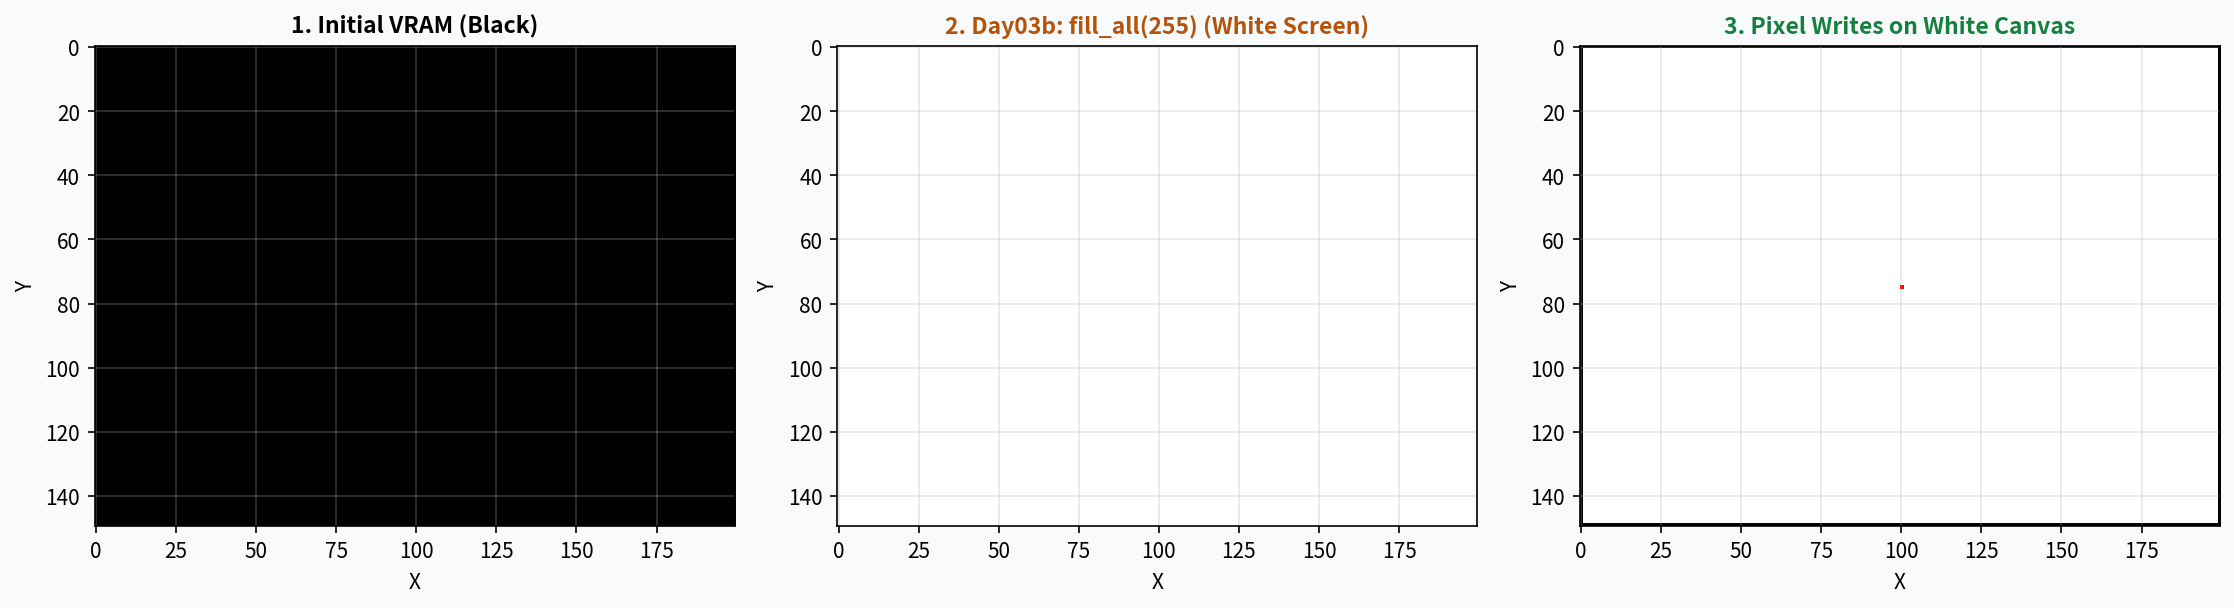

シミュレーション成功: MikanOS Day03b の白色画面初期化と、VRAM ポインタ直接書き込みの動作を完全検証しました！


In [7]:
# === Python UefiGopSimulator による全画面白色クリアとフレームバッファ描画 ===
from common import UefiGopSimulator, UefiGraphicsPixelFormat
import matplotlib.pyplot as plt

# 200x150 のミニ解像度で GOP シミュレータを生成
gop_sim = UefiGopSimulator(
    horizontal_resolution=200,
    vertical_resolution=150,
    pixels_per_scan_line=200,
    pixel_format=UefiGraphicsPixelFormat.PixelRedGreenBlueReserved8BitPerColor,
)

# 1. 初期状態（全画素黒）
img_black = gop_sim.to_rgb_matrix().copy()

# 2. MikanOS Day03b: frame_buffer[i] = 255 による白色全画面クリア
gop_sim.fill_all(255)
img_white = gop_sim.to_rgb_matrix().copy()

# 3. 白色画面の上にピクセル単位でテスト描画（第4章への布石）
gop_sim.write_pixel(100, 75, 255, 0, 0) # 中央に赤点
# 外周に黒い枠線を描く
for x in range(200):
    gop_sim.write_pixel(x, 0, 0, 0, 0)
    gop_sim.write_pixel(x, 149, 0, 0, 0)
for y in range(150):
    gop_sim.write_pixel(0, y, 0, 0, 0)
    gop_sim.write_pixel(199, y, 0, 0, 0)
img_framed = gop_sim.to_rgb_matrix().copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), facecolor="#F8FAFC")
axes[0].imshow(img_black); axes[0].set_title("1. Initial VRAM (Black)", fontsize=11, fontweight="bold")
axes[1].imshow(img_white); axes[1].set_title("2. Day03b: fill_all(255) (White Screen)", fontsize=11, fontweight="bold", color="#B45309")
axes[2].imshow(img_framed); axes[2].set_title("3. Pixel Writes on White Canvas", fontsize=11, fontweight="bold", color="#15803D")

for ax in axes:
    ax.set_xlabel("X"); ax.set_ylabel("Y")
plt.tight_layout()
plt.show()

print("シミュレーション成功: MikanOS Day03b の白色画面初期化と、VRAM ポインタ直接書き込みの動作を完全検証しました！")


## 6. 本節のまとめと次節（3.5 カーネルからピクセルを描く）への架け橋

### 6.1 本節で獲得した知見の総括
1. **UEFI GOP (*Graphics Output Protocol*) の獲得**:
   - レガシー BIOS の 16ビットリアルモード切り替えや VGA パレット設定に依存せず、UEFI ブートサービス（`LocateHandleBuffer` と `OpenProtocol`）を通じて 64ビット高解像度リニアフレームバッファを安全に取得できる。
2. **階層ポインタチェーンとモード情報の掌握**:
   - `gop->Mode->FrameBufferBase`（VRAM 物理アドレス）および `gop->Mode->Info`（解像度・フォーマット・ストライド）の 3 段階ポインタチェーン構造を理解した。
3. **走査線ストライド (`PixelsPerScanLine`) の数理**:
   - ハードウェアのメモリアライメントによる不可視パディング領域の存在と、アドレス計算式 $\text{Offset} = (y \times \text{PixelsPerScanLine} + x) \times 4$ の重要性を実証した。
4. **全画面白色クリアの洗練された機構**:
   - 全 VRAM バイトを `255`（`0xFF`）で埋めることにより、ピクセルフォーマットに関わらず画面全体を純白（#FFFFFF）に初期化できることを確かめた。

---

### 6.2 次節（3.5節）への決定的な課題：カーネルへの情報引き渡し
本節では、ピクセルを描画したのはあくまで **ブートローダ（`MikanLoaderPkg/Main.c`）** でした。

しかし、ブートローダはやがて `ExitBootServices` を呼び出して消え去り、以後は独立した **カーネル（`kernel.elf`）** がすべてのハードウェア制御を引き継がなければなりません。

ここで重大な問題が発生します：
> [!WARNING]
> **カーネルは `gBS` も `gop` も持っていない！**
> `ExitBootServices` を呼んだ瞬間、UEFI ブートサービスは破棄され、カーネル側からは `OpenGOP` を呼び出すことは二度とできません。カーネルがピクセルを描くためには、**ブートローダが取得したフレームバッファの情報（ベースアドレス、サイズ、解像度、ピクセルフォーマット）を、カーネルのエントリポイント引数として安全に手渡す** 必要があります。

次節 **3.5「カーネルからピクセルを描く (`osbook_day03c`)」** では、ブートローダからカーネルへの構造体引数受け渡しと、カーネル空間における C++ グラフィックス描画の幕開けに挑みます！